# 02 · Diccionario razonado, población de estudio y jerarquía de producto

Genera el **mapa del proceso** (Componente 1), resume el diccionario razonado
(Anexo A, `outputs/tablas/diccionario_razonado.csv`), define la **población de
estudio** (forma final `*-SKP` con `SKP_PSQ` en la `Ruta Teórica`) y cuantifica la
jerarquía de producto con la que definimos "producto" (Norma | Grado).

In [1]:
import sys
sys.path.insert(0, "..")  # para importar src/

In [2]:
# Población de estudio, jerarquía de producto y mapa del proceso.
import pandas as pd

from src.poblacion import preparar, poblacion, tabla_jerarquia
from src.config import TABLAS_DIR
from src.diagramas import mapa_proceso
from src.visualizacion import estilo, guardar

df, d = preparar()
estilo()

## 1. Mapa del proceso (Componente 1)

/Users/macbookpro/Desktop/ternium/outputs/figuras/mapa_proceso.png


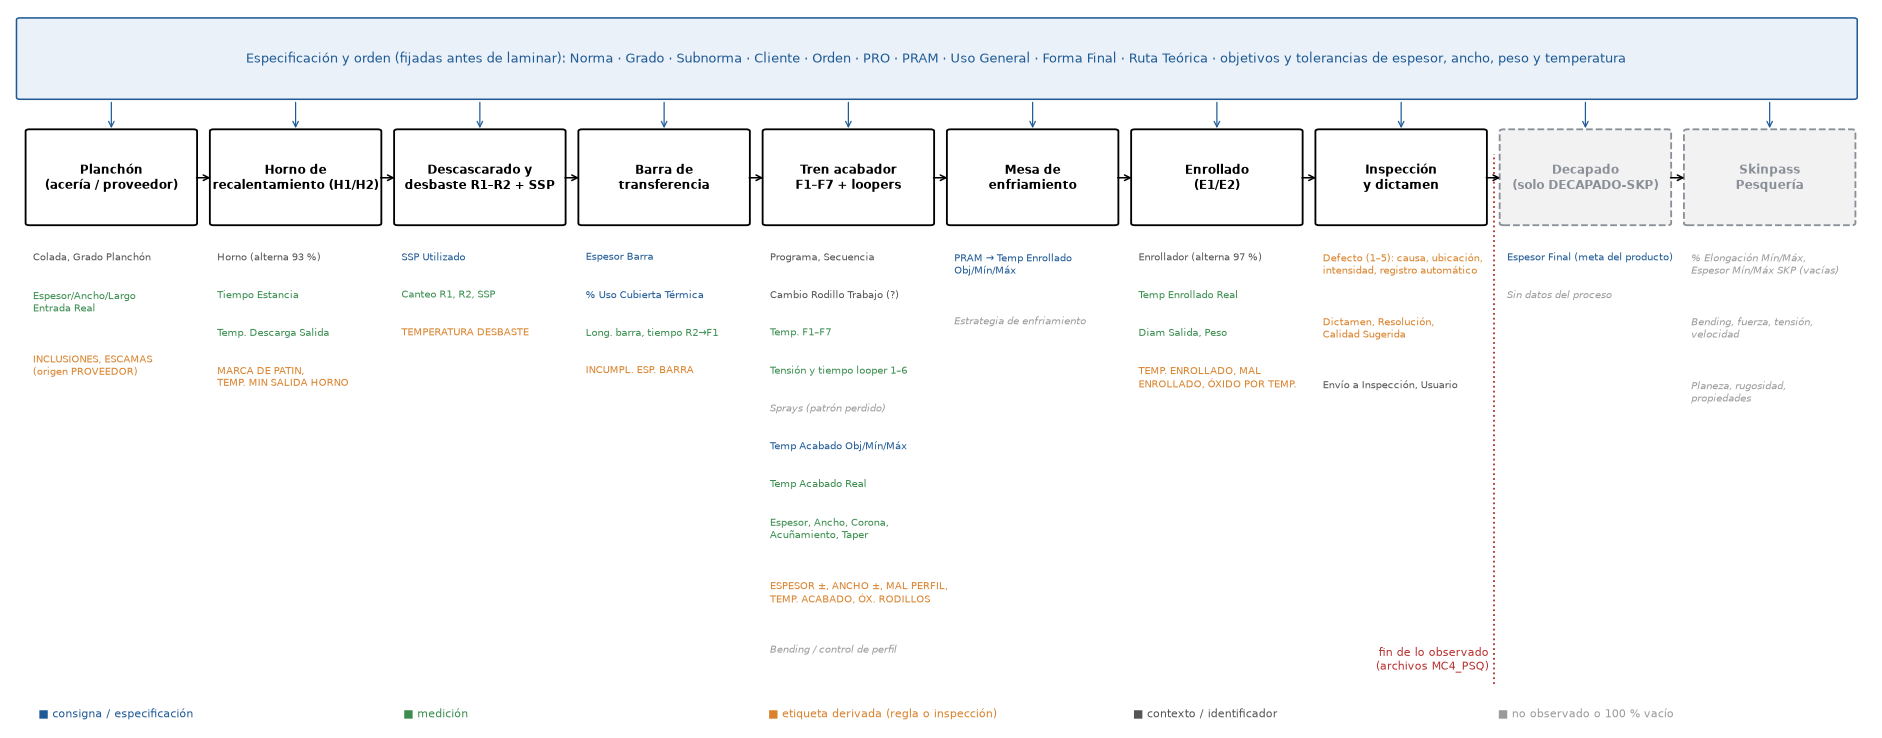

In [3]:
print(guardar(mapa_proceso(), "mapa_proceso"))

## 2. Diccionario razonado (anexo A): resumen

In [4]:
dicc = pd.read_csv(TABLAS_DIR / "diccionario_razonado.csv")
print(f"\nDiccionario razonado: {len(dicc)} variables documentadas")
print(dicc["naturaleza"].value_counts().to_string())
print(dicc["rol"].value_counts().to_string())


Diccionario razonado: 76 variables documentadas
naturaleza
consigna/especificación    30
medición                   24
etiqueta derivada          12
identificador              10
rol
especificación            19
respuesta                 16
material/contexto         13
posterior al resultado    12
palanca                    7
sin uso                    7
identificador              2


## 3. Población de estudio

In [5]:
forma = df["Forma Final"].str.endswith("SKP", na=False)
grupo_forma = pd.Series("Otras formas finales", index=df.index)
grupo_forma[forma] = df.loc[forma, "Forma Final"].str.split("-").str[2] + "-SKP"
destino = pd.Series("Sin Skinpass en la ruta", index=df.index)
destino[df["ruta_skp"]] = "Otros Skinpass (CHU, GUE, RAC)"
destino[df["planta_skp"].eq("SKP_PSQ")] = "Skinpass Pesquería"
tabla_pob = pd.crosstab(grupo_forma, destino)
print("\nRollos por forma final y destino declarado en la Ruta Teórica:")
print(tabla_pob.to_string())

p = poblacion(df)
print(f"\nPoblación de estudio (forma *-SKP y SKP_PSQ en la ruta): {len(p):,} rollos "
      f"({100 * len(p) / len(df):.0f} % del año)")
print("Por tipo de material:", p["tipo_material"].value_counts().to_dict())
por_mes = p.groupby("mes").size()
print(f"Rollos por mes: {por_mes.min():,} – {por_mes.max():,}; meses sin rollos: {(por_mes == 0).sum()}")
print("Programas con rollos de la población:", p["Programa"].nunique())


Rollos por forma final y destino declarado en la Ruta Teórica:
col_0                 Otros Skinpass (CHU, GUE, RAC)  Sin Skinpass en la ruta  Skinpass Pesquería
row_0                                                                                            
CALIENTE-SKP                                    6370                     1047               17509
DECAPADO-SKP                                    1811                     1370               30079
Otras formas finales                             794                    88326                2428

Población de estudio (forma *-SKP y SKP_PSQ en la ruta): 47,588 rollos (32 % del año)
Por tipo de material: {'DECAPADO': 30079, 'CALIENTE': 17509}
Rollos por mes: 20 – 4,501; meses sin rollos: 0
Programas con rollos de la población: 1715


## 4. Jerarquía de producto (qué entenderemos por "producto")

In [6]:
jer = tabla_jerarquia(p)
print("\nJerarquía de producto (población):")
print(jer.to_string(index=False))
TABLAS_DIR.mkdir(parents=True, exist_ok=True)
jer.to_csv(TABLAS_DIR / "jerarquia_producto.csv", index=False)

# Productos con soporte
n_prod = p.groupby("norma_grado", observed=True).size()
print(f"\nProductos (Norma | Grado): {len(n_prod)}; con ≥100 rollos: {(n_prod >= 100).sum()} "
      f"(cubren {100 * n_prod[n_prod >= 100].sum() / len(p):.0f} % de la población)")


Jerarquía de producto (población):
                                  nivel  grupos  mediana de rollos  grupos ≥100 rollos  % de rollos en grupos ≥100  mediana de programas
                       Tipo de material       2            23794.0                   2                       100.0                1567.0
         Familia (Norma) dentro de tipo      49               85.0                  23                        98.1                  38.0
Producto (Norma | Grado) dentro de tipo     364               24.0                  83                        86.7                  11.0
            Producto × rango de espesor     858               14.0                 128                        72.6                   7.0
             Producto × espesor × ancho    1563                9.0                 110                        47.5                   5.0
                         Orden (pedido)   13609                2.0                   1                         0.2                   1.0

Prod